# Análisis de series temporales de defunciones registradas en México por enfermedades respiratorias (2020–2024)

**Objetivo.** Describir la evolución de los registros mensuales de defunción, comparar dos métodos para reconstruir observaciones ocultadas artificialmente y evaluar modelos ARIMA para realizar pronósticos.

**Datos.** Se analizan 51 conteos mensuales, desde enero de 2020 hasta marzo de 2024, contenidos en `COVID_Base_Datos.csv`. Los conteos se construyeron a partir de fechas de defunción (`FECHA_DEF`) de bases de vigilancia epidemiológica. **No deben interpretarse automáticamente como muertes cuya causa comprobada fue COVID-19.**

**Cómo leer el análisis.** Cada sección presenta el objetivo, el cálculo y su interpretación. Para las pruebas estadísticas se utiliza como referencia un nivel de significancia del **5 %** (α = 0.05). Un valor p inferior a 0.05 indica evidencia contra la hipótesis nula correspondiente; no representa la probabilidad de que esa hipótesis sea verdadera.

**Limitación fundamental.** Los registros de febrero y marzo de 2024 son excepcionalmente bajos y su cobertura debe confirmarse. Los pronósticos derivados de la serie son exploratorios; el horizonte final examinado corresponde a **abril de 2024–marzo de 2025**.

## 1. Datos y exploración inicial

Se importa la base mensual y se construye una serie con una observación al inicio de cada mes. Antes de interpretar las gráficas se revisan la cantidad de observaciones, los meses repetidos y las ausencias en el calendario.

In [54]:
#cargamos librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from IPython.display import display
from scipy import stats
from scipy.stats import boxcox_normmax
from statsmodels.formula.api import ols
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, het_arch, normal_ad
from sklearn.metrics import mean_absolute_error, mean_squared_error
from pmdarima import auto_arima

In [55]:
# Carga y organización de la serie mensual
df = pd.read_csv('COVID_Base_Datos.csv')
df['mes'] = pd.to_datetime(df['mes']).dt.to_period('M').dt.to_timestamp()
df['total_mensual'] = pd.to_numeric(df['total_mensual'])
df = df.sort_values('mes')
ts_data = df.set_index('mes')['total_mensual'].astype(float).asfreq('MS')

print('Observaciones:', len(ts_data))
print('Valores faltantes:', ts_data.isna().sum())
print('Meses repetidos:', df['mes'].duplicated().sum())
print('Fechas:', ts_data.index.min().date(), 'a', ts_data.index.max().date())
display(df.head())
display(ts_data.tail(6).to_frame('Total mensual'))

Observaciones: 51
Valores faltantes: 0
Meses repetidos: 0
Fechas: 2020-01-01 a 2024-03-01


,mes,total_mensual
0,2020-01-01,373
1,2020-02-01,439
2,2020-03-01,569
3,2020-04-01,7050
4,2020-05-01,21777


,Total mensual
mes,
2023-10-01,499.0
2023-11-01,511.0
2023-12-01,708.0
2024-01-01,239.0
2024-02-01,11.0
2024-03-01,1.0


**Lectura de la tabla.** La serie tiene **51 meses consecutivos**, sin fechas mensuales duplicadas ni valores faltantes detectados en el calendario. La columna `total_mensual` representa la cantidad de registros del mes correspondiente, no un porcentaje ni una tasa poblacional.

La ausencia de valores `NaN` **no demuestra que la captura de cada mes esté completa**. Los valores de febrero y marzo de 2024 (11 y 1) deben examinarse con particular cuidado. Más adelante se aplica un logaritmo, que exige conteos estrictamente positivos.

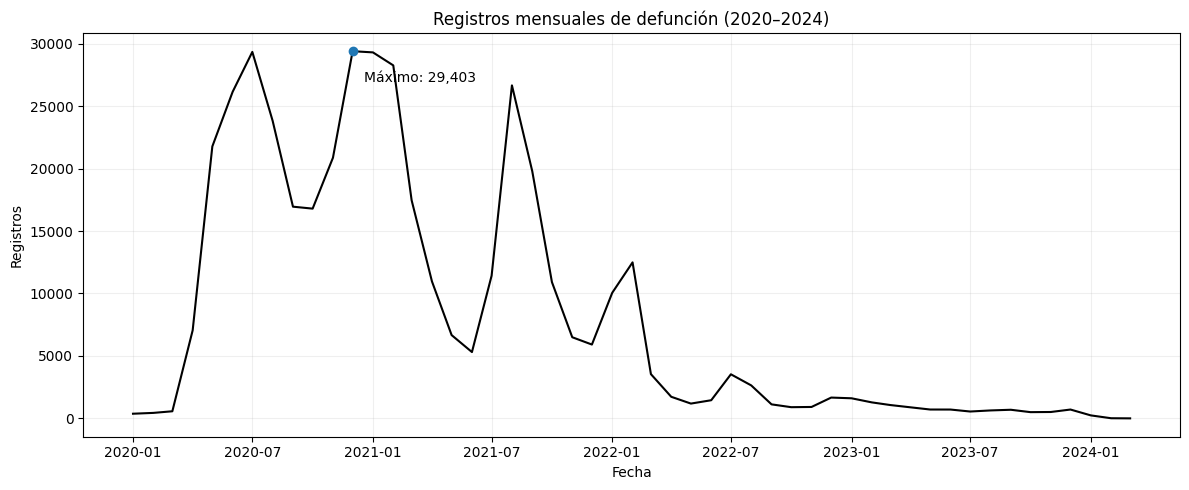

In [56]:
# Evolución histórica
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts_data.index, ts_data, color='black', lw=1.5)
ax.scatter(ts_data.idxmax(), ts_data.max(), color='tab:blue', zorder=3)
ax.annotate(f'Máximo: {ts_data.max():,.0f}', (ts_data.idxmax(), ts_data.max()),
            xytext=(8, -22), textcoords='offset points')
ax.set(title='Registros mensuales de defunción (2020–2024)', xlabel='Fecha', ylabel='Registros')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Cómo interpretar la gráfica histórica.** El eje horizontal muestra los meses y el vertical, el número de registros de defunción de cada mes. El punto señalado corresponde al máximo observado en la base. Los picos describen concentraciones temporales de registros, pero **no permiten identificar por sí solos sus causas**. El descenso hacia 2024 requiere atención especial debido a los valores terminales extremadamente bajos.

### Contexto epidemiológico y visualización anotada

La línea negra representa los registros mensuales. Las líneas verticales de colores añaden **referencias temporales ilustrativas** sobre semáforos epidemiológicos, el primer caso de COVID-19 identificado en México y la vacunación. El color de la línea permite identificar el tipo de referencia y **no mide por sí mismo la intensidad o gravedad de las defunciones**.

**Precaución:** las fechas incluidas en esta gráfica se utilizan como referencias descriptivas y no constituyen una cronología oficial completa ni una clasificación nacional uniforme del semáforo. Para atribuir cada cambio a una fecha exacta habría que contrastarlo con comunicados oficiales y especificar la entidad federativa. La coincidencia de un evento con un pico de la serie **no permite afirmar causalidad**.

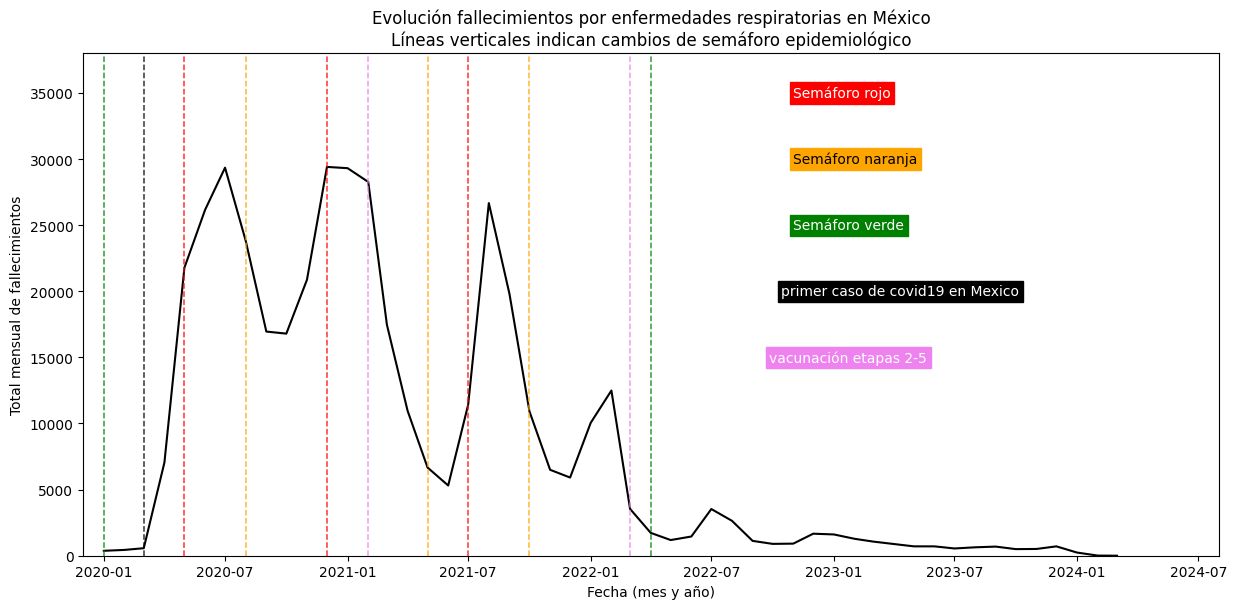

In [57]:
# Serie mensual con marcas epidemiológicas de referencia
marcas = [
    ('2020-01-01', 'Semáforo verde', 'green'),
    ('2020-03-01', 'Primer caso de COVID-19 en México', 'black'),
    ('2020-05-01', 'Semáforo rojo', 'red'),
    ('2020-08-01', 'Semáforo naranja', 'orange'),
    ('2020-12-01', 'Semáforo rojo', 'red'),
    ('2021-02-01', 'Vacunación etapas 2-5', 'violet'),
    ('2021-05-01', 'Semáforo naranja', 'orange'),
    ('2021-07-01', 'Semáforo rojo', 'red'),
    ('2021-10-01', 'Semáforo naranja', 'orange'),
    ('2022-03-01', 'Vacunación etapas 2-5', 'violet'),
    ('2022-04-01', 'Semáforo verde', 'green')
]

fig, ax = plt.subplots(figsize=(12.5, 6.2))
ax.plot(ts_data.index, ts_data.values, color='black', lw=1.5)

for fecha, _, color in marcas:
    ax.axvline(pd.Timestamp(fecha), color=color, linestyle='--', lw=1.1, alpha=0.8)

ax.set_title('Evolución fallecimientos por enfermedades respiratorias en México\nLíneas verticales indican cambios de semáforo epidemiológico')
ax.set_xlabel('Fecha (mes y año)')
ax.set_ylabel('Total mensual de fallecimientos')
ax.set_xlim(ts_data.index.min() - pd.DateOffset(months=1), ts_data.index.max() + pd.DateOffset(months=5))
ax.set_ylim(0, max(ts_data.max() * 1.05, 38000))

# Etiquetas laterales tipo leyenda
x_texto = pd.Timestamp('2022-11-01')
ax.text(x_texto, 35000, 'Semáforo rojo', color='white', ha='left', va='center',
        bbox=dict(facecolor='red', edgecolor='red', boxstyle='square,pad=0.25'))
ax.text(x_texto, 30000, 'Semáforo naranja', color='black', ha='left', va='center',
        bbox=dict(facecolor='orange', edgecolor='orange', boxstyle='square,pad=0.25'))
ax.text(x_texto, 25000, 'Semáforo verde', color='white', ha='left', va='center',
        bbox=dict(facecolor='green', edgecolor='green', boxstyle='square,pad=0.25'))
ax.text(x_texto - pd.DateOffset(days=18), 20000, 'primer caso de covid19 en Mexico', color='white', ha='left', va='center',
        bbox=dict(facecolor='black', edgecolor='black', boxstyle='square,pad=0.25'))
ax.text(x_texto - pd.DateOffset(days=36), 15000, 'vacunación etapas 2-5', color='white', ha='left', va='center',
        bbox=dict(facecolor='violet', edgecolor='violet', boxstyle='square,pad=0.25'))

plt.tight_layout()
plt.show()

## 2. División temporal y experimento de imputación

Para respetar el orden temporal se utiliza una división **aproximada 80/20**, sin mezclar meses: **40 observaciones de entrenamiento** (enero de 2020–abril de 2023) y **11 observaciones de prueba** (mayo de 2023–marzo de 2024). Como 51 no es divisible exactamente en cinco partes, al tomar la parte entera del 80 % quedan **40/51 = 78.4 %** para entrenamiento y **11/51 = 21.6 %** para prueba.

Los meses de prueba no intervienen en la estimación ni en la selección de modelos por AICc. Por separado, se ocultan **cuatro observaciones conocidas del entrenamiento** para evaluar dos métodos de imputación. Estos faltantes son *artificiales*: los modelos ARIMA se ajustan con el **entrenamiento original**, no con los datos imputados.


Entrenamiento: 40 meses (2020-01 a 2023-04)
Prueba: 11 meses (2023-05 a 2024-03)


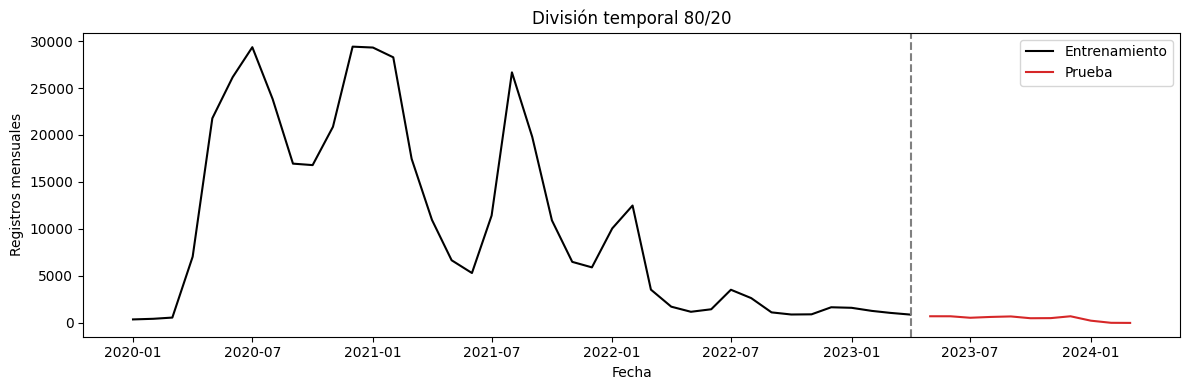

In [58]:
# División cronológica: 80 % entrenamiento, 20 % prueba
n_train = int(len(ts_data) * 0.8)
train_ts = ts_data.iloc[:n_train]
test_ts = ts_data.iloc[n_train:]
print(f'Entrenamiento: {len(train_ts)} meses ({train_ts.index.min():%Y-%m} a {train_ts.index.max():%Y-%m})')
print(f'Prueba: {len(test_ts)} meses ({test_ts.index.min():%Y-%m} a {test_ts.index.max():%Y-%m})')

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_ts.index, train_ts, label='Entrenamiento', color='black')
ax.plot(test_ts.index, test_ts, label='Prueba', color='tab:red')
ax.axvline(train_ts.index[-1], ls='--', color='gray')
ax.set(title='División temporal 80/20', xlabel='Fecha', ylabel='Registros mensuales')
ax.legend()
plt.tight_layout()
plt.show()

**¿Por qué separar entrenamiento y prueba?** Se estiman los parámetros del modelo utilizando los **40 primeros meses**. Después se pronostican los **11 meses siguientes** y se comparan con sus valores observados. La división reproduce una evaluación fuera de muestra, aunque el resultado sigue dependiendo del periodo y del horizonte elegidos.


In [59]:
# Ocultar cuatro observaciones de entrenamiento, con selección reproducible
np.random.seed(123)
posiciones = np.random.choice(len(train_ts), size=4, replace=False)
ts_na = train_ts.copy()
valores_reales = train_ts.iloc[posiciones]
ts_na.iloc[posiciones] = np.nan

print('Meses ocultados:')
display(valores_reales.sort_index().to_frame('Valor observado'))

Meses ocultados:


,Valor observado
mes,
2020-07-01,29346.0
2020-11-01,20873.0
2021-01-01,29307.0
2023-03-01,1069.0


In [60]:
# Imputación con un modelo estructural de Kalman
modelo_kalman = UnobservedComponents(ts_na, level='local linear trend', seasonal=12)
ajuste_kalman = modelo_kalman.fit(disp=False)
estimaciones = ajuste_kalman.get_prediction(information_set='smoothed').predicted_mean
ts_kalman = ts_na.fillna(estimaciones)

# Aproximación estacional: STL e interpolación
tendencia_temporal = ts_na.interpolate()
componente_estacional = STL(tendencia_temporal, period=12, seasonal=11, robust=True).fit().seasonal
ts_stl = ts_na.fillna((ts_na - componente_estacional).interpolate() + componente_estacional)

# Error únicamente en las cuatro observaciones ocultas
comparacion_imputacion = pd.DataFrame({
    'Observado': valores_reales,
    'Kalman': ts_kalman.loc[valores_reales.index],
    'STL + interpolación': ts_stl.loc[valores_reales.index]
}).sort_index()
rmse_kalman = np.sqrt(np.mean((comparacion_imputacion['Observado'] - comparacion_imputacion['Kalman'])**2))
rmse_stl = np.sqrt(np.mean((comparacion_imputacion['Observado'] - comparacion_imputacion['STL + interpolación'])**2))

display(comparacion_imputacion.round(2))
print(f'RMSE Kalman: {rmse_kalman:.2f} | RMSE STL + interpolación: {rmse_stl:.2f}')

,Observado,Kalman,STL + interpolación
mes,,,
2020-07-01,29346.0,24459.44,24987.99
2020-11-01,20873.0,23051.36,23099.32
2021-01-01,29307.0,28012.98,14515.01
2023-03-01,1069.0,-274.48,1103.46


RMSE Kalman: 2832.98 | RMSE STL + interpolación: 7790.26


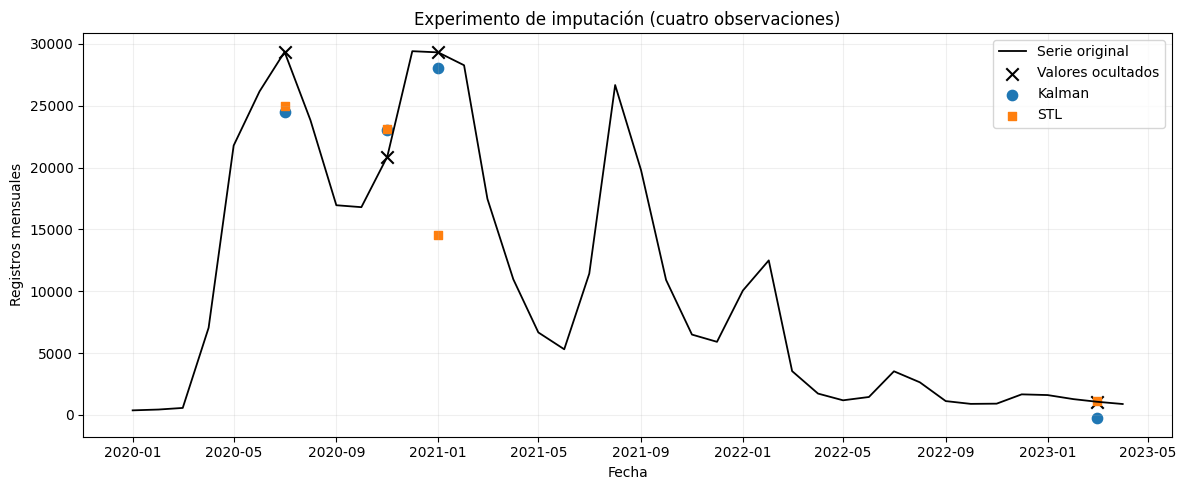

In [61]:
# Comparación visual de valores ocultos e imputaciones
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_ts.index, train_ts, color='black', lw=1.3, label='Serie original')
ax.scatter(comparacion_imputacion.index, comparacion_imputacion['Observado'], marker='x', s=80, color='black', label='Valores ocultados')
ax.scatter(comparacion_imputacion.index, comparacion_imputacion['Kalman'], s=55, color='tab:blue', label='Kalman')
ax.scatter(comparacion_imputacion.index, comparacion_imputacion['STL + interpolación'], marker='s', s=40, color='tab:orange', label='STL')
ax.set(title='Experimento de imputación (cuatro observaciones)', xlabel='Fecha', ylabel='Registros mensuales')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretación de la imputación.** Se ocultaron cuatro meses del entrenamiento para comparar sus valores verdaderos con las reconstrucciones de Kalman y de STL más interpolación.

El **RMSE** mide la magnitud del error de reconstrucción y penaliza más los errores grandes. Para estos meses se obtuvo **RMSE = 2,833.01 con Kalman** frente a **RMSE = 7,790.26 con STL más interpolación**; Kalman tuvo menor error **en este experimento específico**.

Un detalle importante: Kalman reconstruyó marzo de 2023 con aproximadamente **−274.51 registros**, una cantidad que **no es válida como conteo físico de defunciones**. Esto muestra que el modelo estructural no restringe automáticamente las estimaciones a valores no negativos. La comparación se mantiene como un ejercicio metodológico, no como sustitución de registros oficiales. Además, el suavizado de Kalman aprovecha datos anteriores y posteriores a cada mes oculto, de modo que esta reconstrucción retrospectiva no equivale a un pronóstico futuro.


## 3. Análisis descriptivo y estacionariedad

Primero se estudia el comportamiento temporal sin imponer todavía un modelo ARIMA. Se exploran la tendencia general, la variación estacional y la relación entre meses sucesivos.

**Estacionariedad** significa, de forma aproximada, que las propiedades estadísticas de la serie, como su media y su variabilidad, no cambian sistemáticamente con el tiempo. **Estacionalidad**, en cambio, se refiere a patrones que pueden repetirse cada cierto número de periodos. No son sinónimos.

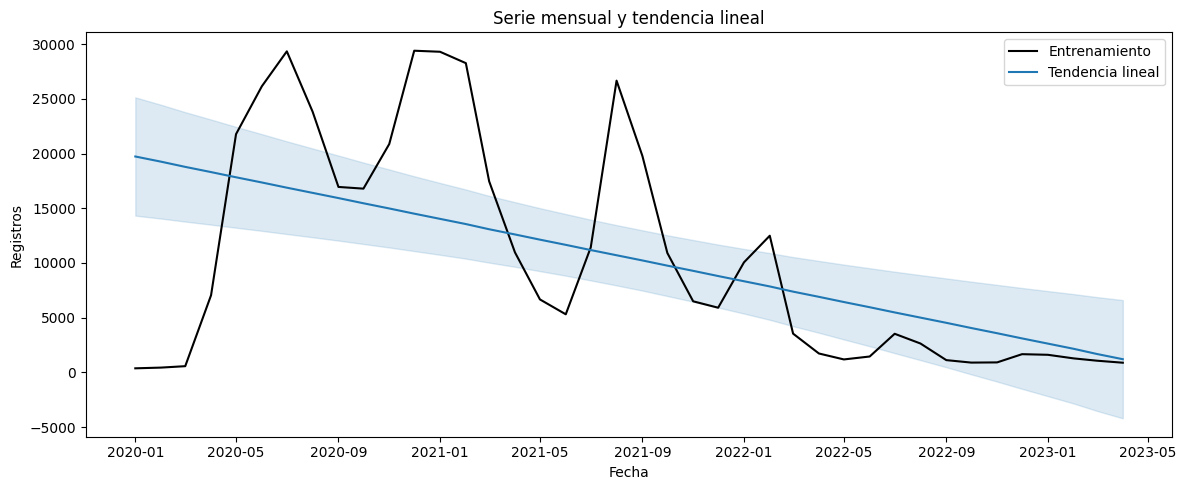

Breusch–Pagan (residuos de regresión descriptiva): p = 0.000109


In [62]:
# Serie observada y tendencia lineal descriptiva
ts_modelo = train_ts.copy()
df_regresion = pd.DataFrame({'fecha': ts_modelo.index, 'valor': ts_modelo.values})
df_regresion['tiempo'] = np.arange(len(df_regresion))
modelo_lineal = ols('valor ~ tiempo', data=df_regresion).fit()
intervalos_lineal = modelo_lineal.get_prediction().summary_frame()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts_modelo.index, ts_modelo, color='black', label='Entrenamiento')
ax.plot(ts_modelo.index, modelo_lineal.fittedvalues, color='tab:blue', label='Tendencia lineal')
ax.fill_between(ts_modelo.index, intervalos_lineal['mean_ci_lower'], intervalos_lineal['mean_ci_upper'], color='tab:blue', alpha=0.15)
ax.set(title='Serie mensual y tendencia lineal', xlabel='Fecha', ylabel='Registros')
ax.legend()
plt.tight_layout()
plt.show()

bp = het_breuschpagan(modelo_lineal.resid, modelo_lineal.model.exog, robust=True)
print(f'Breusch–Pagan (residuos de regresión descriptiva): p = {bp[1]:.6f}')

### ¿Qué indica Breusch–Pagan?

Sobre los datos de entrenamiento se ajusta una **regresión lineal descriptiva**. Los residuos son las diferencias entre los registros observados y los valores de la recta.

**Breusch–Pagan** contrasta la hipótesis nula de **varianza constante de esos residuos** (homocedasticidad). El resultado fue **p = 0.000109**, menor que 0.05. Por tanto, se rechaza esa hipótesis: hay evidencia de que la dispersión de los errores alrededor de la recta **no es constante**.

**Alcance:** esta prueba corresponde a la regresión descriptiva, **no al ARIMA**. La banda que rodea la recta no representa intervalos de predicción de defunciones futuras.


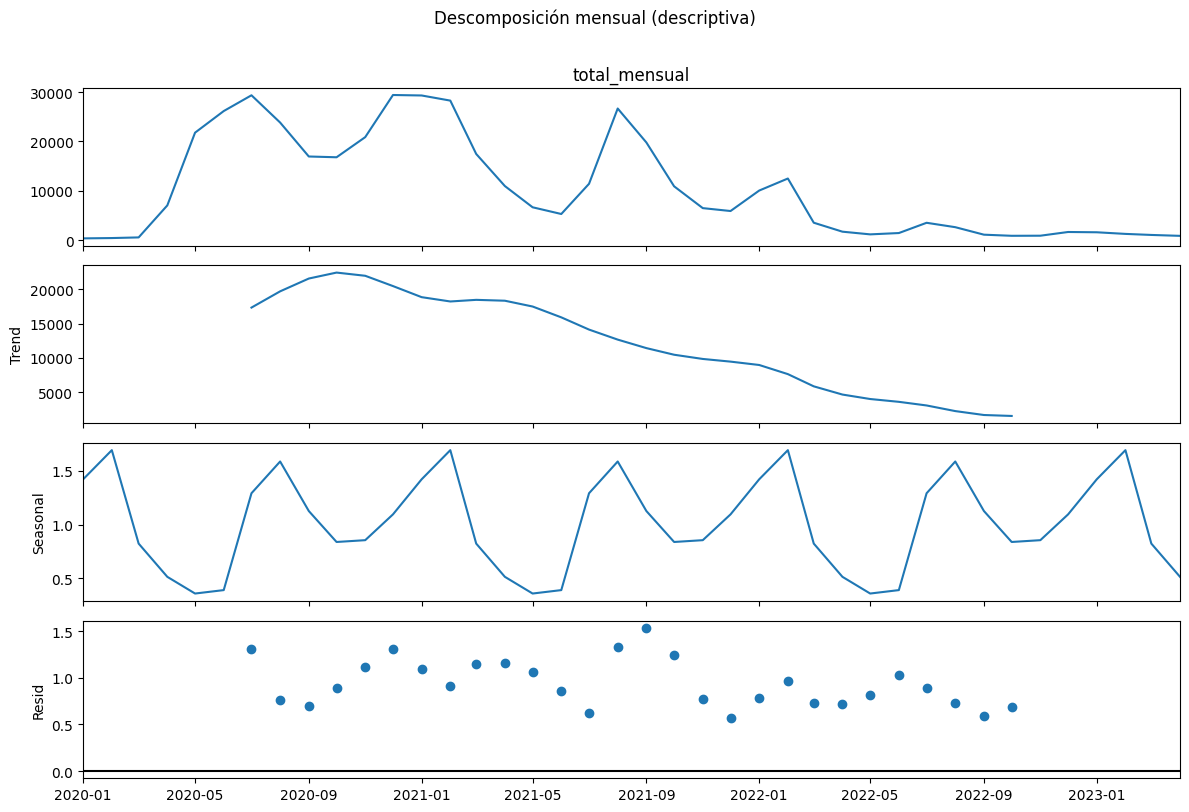

In [63]:
# Descomposición multiplicativa (descriptiva)
descomposicion = seasonal_decompose(ts_modelo, model='multiplicative', period=12)
fig = descomposicion.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Descomposición mensual (descriptiva)', y=1.01)
plt.tight_layout()
plt.show()

**¿Cómo leer la descomposición?** Una descomposición multiplicativa intenta distinguir tres partes: **tendencia** (movimiento general), **componente estacional** (variaciones que podrían repetirse cada doce meses) y **residuo** (lo que esas partes no explican). Al ser multiplicativa, los componentes se interpretan en términos relativos al nivel de la serie.

La serie de entrenamiento tiene menos de cuatro años completos, por lo que la forma exacta de una supuesta estacionalidad anual es **incierta**. Esta figura sirve para explorar, no para confirmar que existe un patrón anual estable.

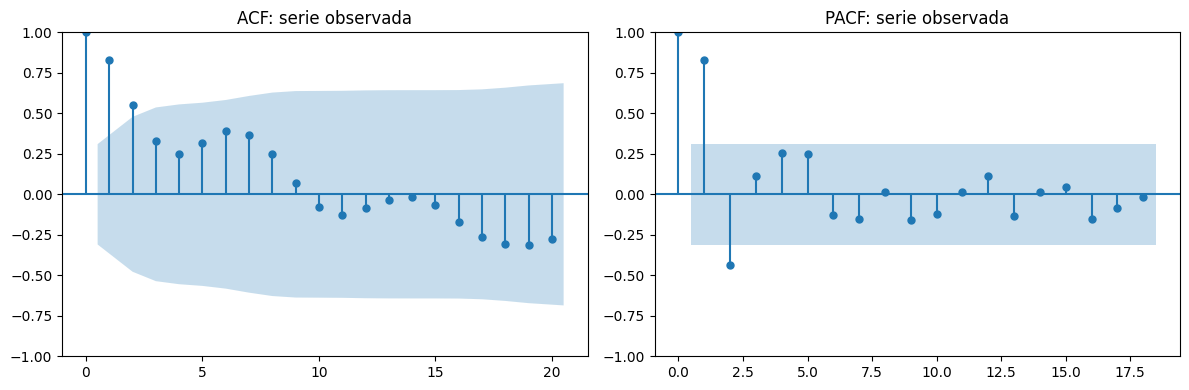

In [64]:
# ACF y PACF de la serie original
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ts_modelo, lags=20, ax=ax[0])
plot_pacf(ts_modelo, lags=18, method='ywm', ax=ax[1])
ax[0].set_title('ACF: serie observada')
ax[1].set_title('PACF: serie observada')
plt.tight_layout()
plt.show()

**ACF y PACF.** Un *rezago* de 1 compara cada mes con el anterior; un rezago de 12 compara meses separados por un año. La **ACF** muestra la correlación de la serie con sus propios rezagos. La **PACF** evalúa la relación directa con un rezago después de descontar la influencia de rezagos intermedios.

Las barras que rebasan las bandas de referencia sugieren correlaciones relevantes, aunque esas bandas son aproximadas. En una serie no estacionaria, las correlaciones pueden persistir por la tendencia, por lo que **ACF y PACF no seleccionan solas el modelo ARIMA**.

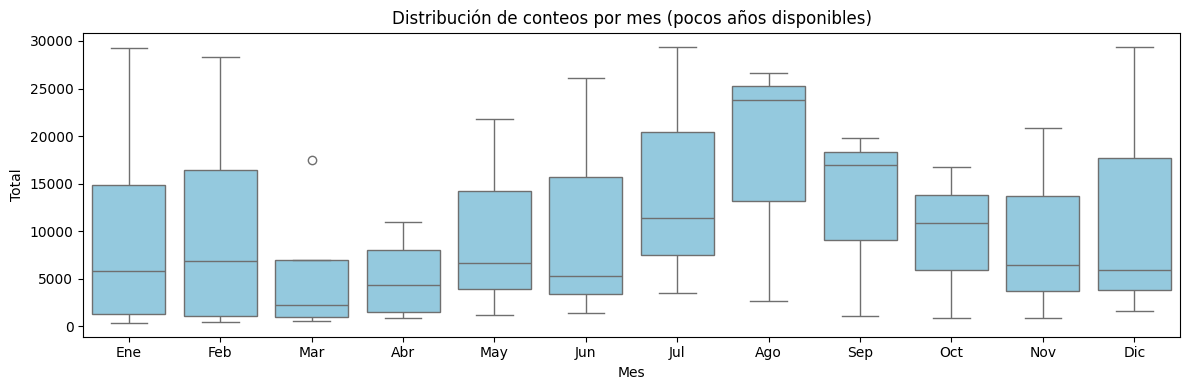

In [65]:
# Distribución por mes del calendario
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
df_meses = pd.DataFrame({'Mes': pd.Categorical([meses[m-1] for m in ts_modelo.index.month], categories=meses, ordered=True), 'Total': ts_modelo.values})
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df_meses, x='Mes', y='Total', color='skyblue', ax=ax)
ax.set_title('Distribución de conteos por mes (pocos años disponibles)')
plt.tight_layout()
plt.show()

**¿Qué representa el diagrama de cajas?** Cada caja resume los conteos registrados en el mismo mes calendario a lo largo de varios años. La línea central representa la mediana y la caja contiene el 50 % central de los valores.

En el entrenamiento hay **pocas observaciones por mes (tres o cuatro)**. Una sola observación extrema puede modificar notablemente la caja; por eso esta figura es descriptiva y no demuestra por sí sola la existencia de estacionalidad.


In [66]:
# Pruebas ADF y KPSS sobre entrenamiento observado
adf_original = adfuller(ts_modelo, regression='c', autolag='AIC')
kpss_original = kpss(ts_modelo, regression='c', nlags='auto')
print(f'ADF: estadístico = {adf_original[0]:.4f}, p = {adf_original[1]:.6f}')
print(f'KPSS: estadístico = {kpss_original[0]:.4f}, p = {kpss_original[1]:.6f}')

ADF: estadístico = -0.5681, p = 0.878038
KPSS: estadístico = 0.5577, p = 0.028678


C:\Users\PC\AppData\Local\Temp\ipykernel_20672\907834410.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_original = adfuller(ts_modelo, regression='c', autolag='AIC')
C:\Users\PC\AppData\Local\Temp\ipykernel_20672\907834410.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_original = kpss(ts_modelo, regression='c', nla

### Interpretación de ADF y KPSS

Las dos pruebas evalúan la estacionariedad, pero sus hipótesis nulas son diferentes:

| Prueba | Hipótesis nula | Valor p | Interpretación al 5 % |
|---|---|---:|---|
| **ADF** | Existe una raíz unitaria, asociada con no estacionariedad. | **0.878038** | No se rechaza la presencia de raíz unitaria. |
| **KPSS** | La serie es estacionaria alrededor de un nivel constante. | **0.028678** | Se rechaza la estacionariedad respecto al nivel. |

Ambos resultados son compatibles con una serie original **no estacionaria**. No rechazar una hipótesis no significa demostrarla. El tamaño de muestra es de **40 meses** y la conclusión depende de la especificación de cada prueba.


## 4. Transformación logarítmica y primera diferencia

El modelo ARIMA se aplicará al **logaritmo natural** de los conteos. Esto puede reducir la desigualdad de la dispersión a diferentes niveles de la serie: diferencias proporcionales similares pasan a tener magnitudes más comparables. La transformación es válida aquí porque los registros son positivos.

La familia **Box–Cox** permite elegir una transformación según el parámetro λ. Cuando **λ = 0** se utiliza el logaritmo natural. Después se analiza la **primera diferencia**, es decir, el cambio entre el logaritmo de un mes y el del mes anterior. En un ARIMA, aplicar una diferencia corresponde a utilizar **d = 1**.

Lambda estimado: 0.1557 | Lambda utilizado: 0 (logaritmo)


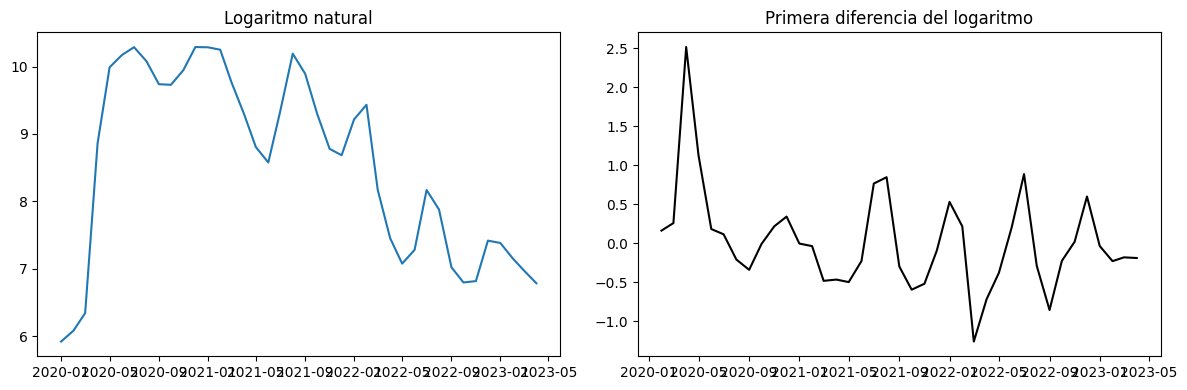

In [67]:
# Box-Cox: estimación de lambda y transformación seleccionada
lambda_estimado = boxcox_normmax(ts_modelo, method='mle')
ts_log = np.log(ts_modelo)
ts_diff1 = ts_log.diff().dropna()
print(f'Lambda estimado: {lambda_estimado:.4f} | Lambda utilizado: 0 (logaritmo)')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ts_log.index, ts_log, color='tab:blue')
ax[0].set_title('Logaritmo natural')
ax[1].plot(ts_diff1.index, ts_diff1, color='black')
ax[1].set_title('Primera diferencia del logaritmo')
plt.tight_layout()
plt.show()

**Resultado de Box–Cox.** El parámetro estimado con los 40 meses de entrenamiento fue **λ ≈ 0.1557**. Para este análisis se opta por **λ = 0**, que corresponde al logaritmo natural; es una elección de modelación e interpretación, no el valor que maximiza el criterio de Box–Cox.

El logaritmo convierte diferencias multiplicativas en diferencias aditivas y puede atenuar cambios de escala. Después se aplica la **primera diferencia** para estudiar variaciones entre meses. Una reducción en la varianza numérica tras transformar no prueba por sí sola homocedasticidad: también cambió la unidad de medida.


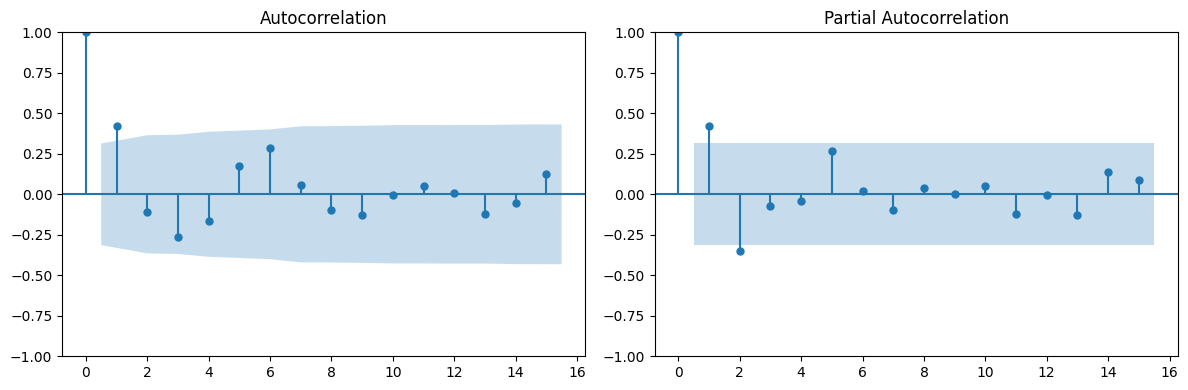

ADF sobre Δ log(y): p = 0.006632


C:\Users\PC\AppData\Local\Temp\ipykernel_20672\1412210526.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(ts_diff1, regression='c', autolag='AIC')


In [68]:
# ACF/PACF de la serie diferenciada y prueba ADF
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ts_diff1, lags=15, ax=ax[0])
plot_pacf(ts_diff1, lags=15, method='ywm', ax=ax[1])
plt.tight_layout()
plt.show()
adf_diff = adfuller(ts_diff1, regression='c', autolag='AIC')
print(f'ADF sobre Δ log(y): p = {adf_diff[1]:.6f}')

**¿Sirvió la primera diferencia?** En la serie **Δ log(y)** la prueba ADF obtuvo **p = 0.006632**. Con α = 0.05, este resultado permite rechazar su hipótesis nula de raíz unitaria y respalda evaluar modelos con **d = 1**. La prueba no garantiza que los residuos posteriores sean normales ni que los pronósticos sean exactos.


## 5. Ajuste y comparación de modelos ARIMA

Un modelo **ARIMA(p,d,q)** utiliza tres componentes: **p** es el orden autorregresivo (relación con valores anteriores), **d** es el número de diferencias aplicadas y **q** es el orden de la media móvil (dependencia respecto a perturbaciones anteriores).

Se comparan varias especificaciones no estacionales sobre los **40 meses originales de entrenamiento, transformados con logaritmo**. El procedimiento automático propone un candidato adicional. Todos se vuelven a ajustar con la misma biblioteca para efectuar la comparación numérica; seleccionar un modelo por un criterio de información no sustituye la comprobación de residuos ni la evaluación sobre los meses de prueba.

In [69]:
# Búsqueda automática sin componente estacional ni deriva
fit_0 = auto_arima(ts_log, d=1, seasonal=False, with_intercept=False,
                   stepwise=True, information_criterion='aicc',
                   suppress_warnings=True, error_action='ignore')
print('Modelo automático:', fit_0.order)

# Reestimación uniforme de los cinco candidatos con statsmodels
fit_0_sm = ARIMA(ts_log, order=fit_0.order, trend='n').fit()
fit_1 = ARIMA(ts_log, order=(0, 1, 0), trend='n').fit()
fit_2 = ARIMA(ts_log, order=(1, 1, 2), trend='n').fit()
fit_3 = ARIMA(ts_log, order=(1, 0, 1), trend='c').fit()
fit_4 = ARIMA(ts_log, order=(1, 1, 0), trend='n').fit()

modelos = {
    f'Automático ARIMA{fit_0.order}': fit_0_sm,
    'ARIMA(0,1,0)': fit_1,
    'ARIMA(1,1,2)': fit_2,
    'ARIMA(1,0,1)': fit_3,
    'ARIMA(1,1,0)': fit_4
}
print('Candidatos:', list(modelos))

Modelo automático: (0, 1, 1)
Candidatos: ['Automático ARIMA(0, 1, 1)', 'ARIMA(0,1,0)', 'ARIMA(1,1,2)', 'ARIMA(1,0,1)', 'ARIMA(1,1,0)']


In [70]:
# Coeficientes e intervalos del 95 %, sin la varianza residual
coeficientes = pd.concat({nombre: pd.DataFrame({
    'Estimación': ajuste.params,
    'Límite inferior': ajuste.conf_int().iloc[:, 0],
    'Límite superior': ajuste.conf_int().iloc[:, 1]
}) for nombre, ajuste in modelos.items()}, names=['Modelo', 'Parámetro']).reset_index()
coeficientes = coeficientes.loc[coeficientes['Parámetro'] != 'sigma2'].copy()
coeficientes['Significativo 5 %'] = ((coeficientes['Límite inferior'] > 0) | (coeficientes['Límite superior'] < 0)).map({True: 'Sí', False: 'No'})
display(coeficientes.round(4))
print('ARIMA(0,1,0) solo estima la varianza de las innovaciones.')

,Modelo,Parámetro,Estimación,Límite inferior,Límite superior,Significativo 5 %
0,"Automático ARIMA(0, 1, 1)",ma.L1,0.6126,0.1443,1.0808,Sí
3,"ARIMA(1,1,2)",ar.L1,0.6075,-3.2177,4.4326,No
4,"ARIMA(1,1,2)",ma.L1,-0.0415,-3.9224,3.8395,No
5,"ARIMA(1,1,2)",ma.L2,-0.4356,-2.5706,1.6995,No
7,"ARIMA(1,0,1)",const,7.9862,6.3992,9.5731,Sí
8,"ARIMA(1,0,1)",ar.L1,0.8460,0.5688,1.1232,Sí
9,"ARIMA(1,0,1)",ma.L1,0.6353,0.1972,1.0734,Sí
11,"ARIMA(1,1,0)",ar.L1,0.4110,-0.1036,0.9257,No


ARIMA(0,1,0) solo estima la varianza de las innovaciones.


**Interpretación de coeficientes e intervalos.** Los términos `ar.L1`, `ma.L1` y `ma.L2` representan dependencias respecto a observaciones o perturbaciones de meses anteriores; `const` es una constante del modelo cuando corresponde.

Un **intervalo de confianza del 95 %** que **no incluye cero** indica que el coeficiente es estadísticamente distinto de cero al nivel aproximado del 5 %. Si lo incluye, **no hay evidencia suficiente** para asegurar que el coeficiente sea distinto de cero. Esta regla usa una aproximación estadística y no obliga automáticamente a eliminar parámetros: también cuentan la estabilidad del ajuste y su capacidad predictiva.

In [71]:
# Comparación AIC, BIC y AICc
comparacion_ic = []
for nombre, ajuste in modelos.items():
    k = len(ajuste.params)
    n = int(ajuste.nobs_effective)
    comparacion_ic.append([nombre, n, k, ajuste.aic, ajuste.bic,
                           ajuste.aic + 2*k*(k+1)/(n-k-1)])

comp = pd.DataFrame(comparacion_ic, columns=['Modelo', 'n efectivo', 'Parámetros', 'AIC', 'BIC', 'AICc']).sort_values('AICc').reset_index(drop=True)
modelo_seleccionado = comp.loc[0, 'Modelo']
ajuste_elegido = modelos[modelo_seleccionado]
orden_elegido = ajuste_elegido.model.order
tendencia_elegida = ajuste_elegido.model.trend

display(comp.round(4))
print('Modelo con menor AICc:', modelo_seleccionado)
print('Selección provisional: revisar residuos y predicción fuera de muestra.')

,Modelo,n efectivo,Parámetros,AIC,BIC,AICc
0,"Automático ARIMA(0, 1, 1)",39,2,67.4234,70.7505,67.7567
1,"ARIMA(1,1,0)",39,2,71.5384,74.8656,71.8718
2,"ARIMA(1,1,2)",39,4,71.1668,77.8211,72.3433
3,"ARIMA(1,0,1)",40,4,72.3484,79.1039,73.4912
4,"ARIMA(0,1,0)",39,1,76.9443,78.6079,77.0524


Modelo con menor AICc: Automático ARIMA(0, 1, 1)
Selección provisional: revisar residuos y predicción fuera de muestra.


### ¿Por qué se seleccionó ARIMA(0,1,1)?

Los criterios **AIC**, **BIC** y **AICc** combinan calidad del ajuste con una penalización por complejidad. El **AICc** introduce una corrección por muestra pequeña; un valor menor favorece al modelo correspondiente **entre los candidatos comparados**.

Con 40 meses de entrenamiento, el menor **AICc = 67.7567** corresponde a **ARIMA(0,1,1)**. La selección se realiza sin utilizar los 11 meses de prueba. Esto no significa que el ARIMA sea el único modelo adecuado ni garantiza una precisión superior en periodos posteriores; por ello se examinan residuos y errores fuera de muestra.


### Diagnóstico de residuos

Un **residuo** es la diferencia entre el valor observado (en la escala del ajuste) y el valor que explica el modelo. Un modelo adecuado debería dejar residuos sin un patrón temporal claro; además, interesa evaluar su distribución y su variabilidad.

Se utilizan pruebas diferentes porque **cada una responde una pregunta distinta**:

| Prueba | Hipótesis nula (H₀) | ¿Qué significa un p menor que 0.05? |
|---|---|---|
| **t de la media residual** | La media de los residuos es igual a cero. | Evidencia de media residual distinta de cero. |
| **Ljung–Box (10 y 20 rezagos)** | No hay autocorrelación conjunta hasta el rezago examinado, considerando los grados de libertad del ARIMA. | Evidencia de dependencia temporal aún no explicada. |
| **Anderson–Darling (AD)** | Los residuos siguen una distribución normal. | Evidencia contra la normalidad. |
| **ARCH-LM (5 rezagos)** | No hay efecto ARCH (heterocedasticidad condicional) hasta el rezago elegido. | Evidencia de variación condicional no constante de tipo ARCH. |
| **ADF de residuos** | Los residuos presentan una raíz unitaria. | Evidencia contra la presencia de raíz unitaria. |

En todos los casos, **p ≥ 0.05 no demuestra que se cumpla la hipótesis nula**. La cantidad de meses disponibles y los supuestos de cada prueba limitan el alcance de las conclusiones.

In [72]:
# Una tabla de pruebas para los cinco modelos
resumen_residuos = []
for nombre, ajuste in modelos.items():
    residuos = np.asarray(ajuste.resid, dtype=float)[ajuste.loglikelihood_burn:]
    orden = ajuste.model.order
    gl = orden[0] + orden[2]
    resumen_residuos.append({
        'Modelo': nombre,
        'Media residual (p)': stats.ttest_1samp(residuos, 0).pvalue,
        'Ljung-Box 10 (p)': acorr_ljungbox(residuos, lags=[10], model_df=gl)['lb_pvalue'].iloc[0],
        'Ljung-Box 20 (p)': acorr_ljungbox(residuos, lags=[20], model_df=gl)['lb_pvalue'].iloc[0],
        'Normalidad AD (p)': normal_ad(residuos)[1],
        'ARCH-LM 5 (p)': het_arch(residuos, nlags=5)[1],
        'ADF residual (p)': adfuller(residuos, regression='c', autolag='AIC')[1]
    })

tabla_diagnosticos = pd.DataFrame(resumen_residuos).set_index('Modelo')
display(tabla_diagnosticos.round(6))

c:\Users\PC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
C:\Users\PC\AppData\Local\Temp\ipykernel_20672\679157909.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF residual (p)': adfuller(residuos, regression='c', autolag='AIC')[1]
c:\Users\PC\AppData\Local

,Media residual (p),Ljung-Box 10 (p),Ljung-Box 20 (p),Normalidad AD (p),ARCH-LM 5 (p),ADF residual (p)
Modelo,,,,,,
"Automático ARIMA(0, 1, 1)",0.871805,0.568783,0.906404,0.002320,0.920883,0.000068
"ARIMA(0,1,0)",0.830099,0.038228,0.262090,0.010019,0.971947,0.006632
"ARIMA(1,1,2)",0.830949,0.423567,0.868595,0.001422,0.870646,0.000485
"ARIMA(1,0,1)",0.853412,0.214643,0.577652,0.000493,0.724248,0.363824
"ARIMA(1,1,0)",0.906075,0.109111,0.412900,0.001742,0.970597,0.000003


### Interpretación de los diagnósticos del modelo seleccionado

Para el modelo **ARIMA(0,1,1)**, los diagnósticos sobre los residuos dan:

| Prueba | Valor p | Interpretación con α = 0.05 |
|---|---:|---|
| Media residual (t) | **0.871805** | No se detecta una media distinta de cero. |
| Ljung–Box, 10 rezagos | **0.568783** | No se detecta autocorrelación conjunta significativa. |
| Ljung–Box, 20 rezagos | **0.906404** | Tampoco se detecta autocorrelación significativa en este contraste. |
| Anderson–Darling | **0.002320** | Se rechaza la normalidad de los residuos. |
| ARCH-LM, 5 rezagos | **0.920882** | No se detecta un efecto ARCH significativo. |
| ADF residual | **0.000068** | Se rechaza la hipótesis de raíz unitaria residual. |

**Balance:** el modelo no presenta evidencia de autocorrelación residual en los rezagos evaluados, pero **sus residuos no siguen una distribución normal según Anderson–Darling**. Ningún valor p alto demuestra que el supuesto se cumpla necesariamente; además, estas pruebas se aplican a una serie relativamente corta.


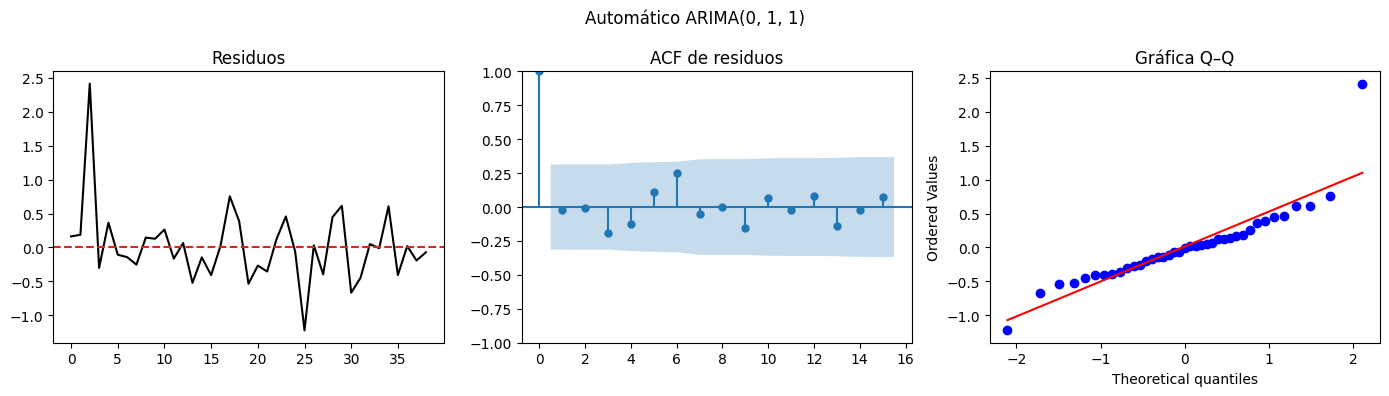

In [73]:
# Diagnóstico visual del candidato seleccionado
residuos_elegidos = np.asarray(ajuste_elegido.resid)[ajuste_elegido.loglikelihood_burn:]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(residuos_elegidos, color='black')
ax[0].axhline(0, color='tab:red', ls='--')
ax[0].set_title('Residuos')
plot_acf(residuos_elegidos, lags=15, ax=ax[1])
ax[1].set_title('ACF de residuos')
stats.probplot(residuos_elegidos, dist='norm', plot=ax[2])
ax[2].set_title('Gráfica Q–Q')
fig.suptitle(modelo_seleccionado)
plt.tight_layout()
plt.show()

**Lectura de los gráficos de diagnóstico.** En el gráfico de residuos se busca que no aparezcan tendencias, ciclos ni cambios persistentes de dispersión. La **ACF de residuos** permite detectar correlaciones que el modelo no logró capturar. En la **gráfica Q–Q**, los puntos se comparan con una recta de referencia: desviaciones importantes sugieren que la distribución de residuos no es normal.

Los contrastes numéricos y los gráficos se complementan; ninguna prueba aislada garantiza un modelo perfecto. Las conclusiones deben contrastarse también con los errores calculados sobre los meses de prueba.

## 6. Pronóstico de once meses y evaluación

Se pronostican **mayo de 2023 a marzo de 2024**, los **11 meses reservados para prueba**. El modelo ajustado trabaja con logaritmos y se utiliza `exp()` para devolver sus pronósticos e intervalos a la escala original.

La columna **«Pronóstico»** corresponde a una **mediana predictiva** bajo el supuesto lognormal, no necesariamente a la media esperada de los conteos. Los intervalos del **80 % y 95 %** son intervalos de **predicción de observaciones futuras**, no intervalos de confianza para una media.


,Pronóstico,Inferior 80%,Superior 80%,Inferior 95%,Superior 95%
Mes,,,,,
2023-05-01,847.35,422.87,1697.90,292.70,2453.04
2023-06-01,847.35,226.63,3168.19,112.75,6368.04
2023-07-01,847.35,150.11,4783.06,60.05,11956.45
2023-08-01,847.35,107.79,6661.13,36.19,19842.21
2023-09-01,847.35,81.07,8857.03,23.40,30678.53
2023-10-01,847.35,62.89,11417.02,15.87,45234.47
2023-11-01,847.35,49.91,14387.03,11.14,64423.77
2023-12-01,847.35,40.30,17815.08,8.04,89329.94
2024-01-01,847.35,33.01,21752.31,5.92,121232.81


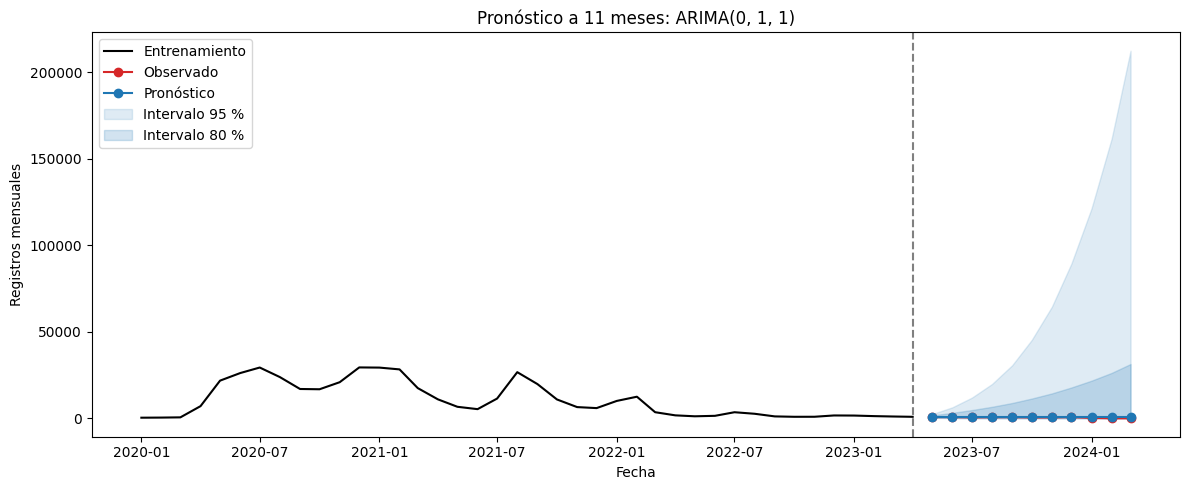

In [74]:
# Pronóstico e intervalos en escala original
pronostico_test = ajuste_elegido.get_forecast(steps=len(test_ts))
ic80 = pronostico_test.conf_int(alpha=0.20)
ic95 = pronostico_test.conf_int(alpha=0.05)
original = pd.DataFrame({
    'Pronóstico': np.exp(pronostico_test.predicted_mean.to_numpy()),
    'Inferior 80%': np.exp(ic80.iloc[:, 0].to_numpy()),
    'Superior 80%': np.exp(ic80.iloc[:, 1].to_numpy()),
    'Inferior 95%': np.exp(ic95.iloc[:, 0].to_numpy()),
    'Superior 95%': np.exp(ic95.iloc[:, 1].to_numpy())
}, index=test_ts.index)
original.index.name = 'Mes'
display(original.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train_ts.index, train_ts, color='black', label='Entrenamiento')
ax.plot(test_ts.index, test_ts, color='tab:red', marker='o', label='Observado')
ax.plot(original.index, original['Pronóstico'], color='tab:blue', marker='o', label='Pronóstico')
ax.fill_between(original.index, original['Inferior 95%'], original['Superior 95%'], color='tab:blue', alpha=0.14, label='Intervalo 95 %')
ax.fill_between(original.index, original['Inferior 80%'], original['Superior 80%'], color='tab:blue', alpha=0.20, label='Intervalo 80 %')
ax.axvline(train_ts.index[-1], color='gray', ls='--')
ax.set(title=f'Pronóstico a {len(test_ts)} meses: ARIMA{orden_elegido}', xlabel='Fecha', ylabel='Registros mensuales')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación del pronóstico de prueba.** La especificación seleccionada produce una **mediana aproximada de 847.35 registros por mes** durante el horizonte **mayo de 2023–marzo de 2024**. La trayectoria central es constante, lo que es compatible con ARIMA(0,1,1) sin deriva, pero **no supone que el valor observado deba ser constante**.

A medida que se pronostican meses más lejanos, los intervalos se ensanchan. Por ejemplo, para marzo de 2024 el límite superior del intervalo predictivo del 95 % supera los **200,000 registros**. Esa amplitud expresa mucha incertidumbre y hace inadecuado juzgar el modelo únicamente por la cobertura del intervalo. La siguiente gráfica recorta la escala vertical para facilitar la lectura de los valores bajos, sin modificar los cálculos.


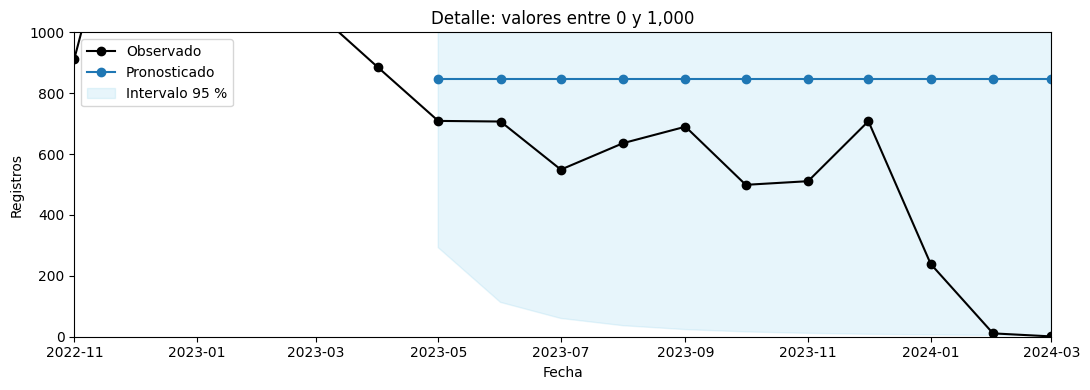

El recorte de los ejes no modifica el pronóstico; puede ocultar límites superiores del intervalo.


In [75]:
# Detalle del periodo de prueba
detalle = ts_data.iloc[n_train-6:]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(detalle.index, detalle, color='black', marker='o', label='Observado')
ax.plot(original.index, original['Pronóstico'], color='tab:blue', marker='o', label='Pronosticado')
ax.fill_between(original.index, original['Inferior 95%'], original['Superior 95%'], alpha=0.2, color='skyblue', label='Intervalo 95 %')
ax.set(xlim=(detalle.index[0], original.index[-1]), ylim=(0, 1000), title='Detalle: valores entre 0 y 1,000', xlabel='Fecha', ylabel='Registros')
ax.legend()
plt.tight_layout()
plt.show()
print('El recorte de los ejes no modifica el pronóstico; puede ocultar límites superiores del intervalo.')

In [76]:
# Evaluación frente a un pronóstico ingenuo constante
comparacion_test = pd.DataFrame({'Observado': test_ts, 'ARIMA': original['Pronóstico']})
comparacion_test['Ingenuo'] = float(train_ts.iloc[-1])
comparacion_test['Dentro del IC 95 %'] = test_ts.between(original['Inferior 95%'], original['Superior 95%'])
metricas = pd.DataFrame({
    'Modelo': ['ARIMA', 'Ingenuo'],
    'MAE': [mean_absolute_error(test_ts, comparacion_test['ARIMA']),
            mean_absolute_error(test_ts, comparacion_test['Ingenuo'])],
    'RMSE': [np.sqrt(mean_squared_error(test_ts, comparacion_test['ARIMA'])),
             np.sqrt(mean_squared_error(test_ts, comparacion_test['Ingenuo']))]
})
display(metricas.round(2))
print(f"Cobertura observada del intervalo 95 %: {comparacion_test['Dentro del IC 95 %'].mean():.1%} ({len(test_ts)} meses)")
display(comparacion_test.round(2))

# Sensibilidad descriptiva de errores usando los meses de prueba hasta enero de 2024
prueba_hasta_enero = comparacion_test.loc[:'2024-01']
print('MAE ARIMA hasta enero 2024:', round(mean_absolute_error(prueba_hasta_enero['Observado'], prueba_hasta_enero['ARIMA']), 2))

,Modelo,MAE,RMSE
0,ARIMA,369.17,450.96
1,Ingenuo,406.82,482.27


Cobertura observada del intervalo 95 %: 90.9% (11 meses)


,Observado,ARIMA,Ingenuo,Dentro del IC 95 %
Mes,,,,
2023-05-01,709.0,847.35,885.0,True
2023-06-01,707.0,847.35,885.0,True
2023-07-01,549.0,847.35,885.0,True
2023-08-01,636.0,847.35,885.0,True
2023-09-01,690.0,847.35,885.0,True
2023-10-01,499.0,847.35,885.0,True
2023-11-01,511.0,847.35,885.0,True
2023-12-01,708.0,847.35,885.0,True
2024-01-01,239.0,847.35,885.0,True


MAE ARIMA hasta enero 2024: 264.24


### ¿Qué significan MAE, RMSE y cobertura?

- **MAE** (*error absoluto medio*): promedio de las distancias absolutas entre valores previstos y observados; se mide en registros mensuales.
- **RMSE** (*raíz del error cuadrático medio*): también se mide en registros mensuales y penaliza especialmente los errores grandes.
- **Pronóstico ingenuo:** utiliza el último valor de entrenamiento (**885**) para todos los meses de prueba; sirve como referencia sencilla.
- **Cobertura del 95 %:** porcentaje de los 11 meses observados que quedaron dentro de los intervalos predictivos. No evalúa la cercanía de la mediana pronosticada.

El ARIMA obtuvo **MAE = 369.17 y RMSE = 450.96**, frente a **MAE = 406.82 y RMSE = 482.27** del modelo ingenuo. Por estas métricas, ARIMA presentó menor error en los **11 meses evaluados**.

**Cobertura observada:** **10 de 11 meses (90.9 %)** quedaron dentro del intervalo del 95 %. **Marzo de 2024** fue el único fuera. Esta cobertura por sí sola no demuestra calibración adecuada, porque los intervalos son muy amplios y la muestra de prueba es pequeña.

Como análisis adicional, al evaluar solamente los meses de prueba **hasta enero de 2024**, el MAE del ARIMA es **264.24**. La diferencia respecto al MAE total muestra la influencia de los dos últimos registros, especialmente bajos.


## 7. Pronóstico exploratorio de doce meses

Con la especificación seleccionada se estima un nuevo ajuste sobre los **51 meses disponibles** para estudiar los doce meses posteriores al último registro (abril de 2024 a marzo de 2025).

**Este ejercicio no verifica que todos los registros estén completos**. Como los últimos conteos disminuyen abruptamente, es posible que el pronóstico responda de manera extrema a esa caída. Por ello debe tratarse como un escenario estadístico exploratorio, no como una predicción epidemiológica definitiva.

,Pronóstico,Inferior 80%,Superior 80%,Inferior 95%,Superior 95%
Mes,,,,,
2024-04-01,0.55,0.25,1.22,0.16,1.85
2024-05-01,0.55,0.11,2.68,0.05,6.19
2024-06-01,0.55,0.07,4.46,0.02,13.49
2024-07-01,0.55,0.05,6.71,0.01,25.18
2024-08-01,0.55,0.03,9.52,0.01,43.00
2024-09-01,0.55,0.02,13.00,0.00,69.25
2024-10-01,0.55,0.02,17.26,0.00,106.82
2024-11-01,0.55,0.01,22.42,0.00,159.43
2024-12-01,0.55,0.01,28.63,0.00,231.73


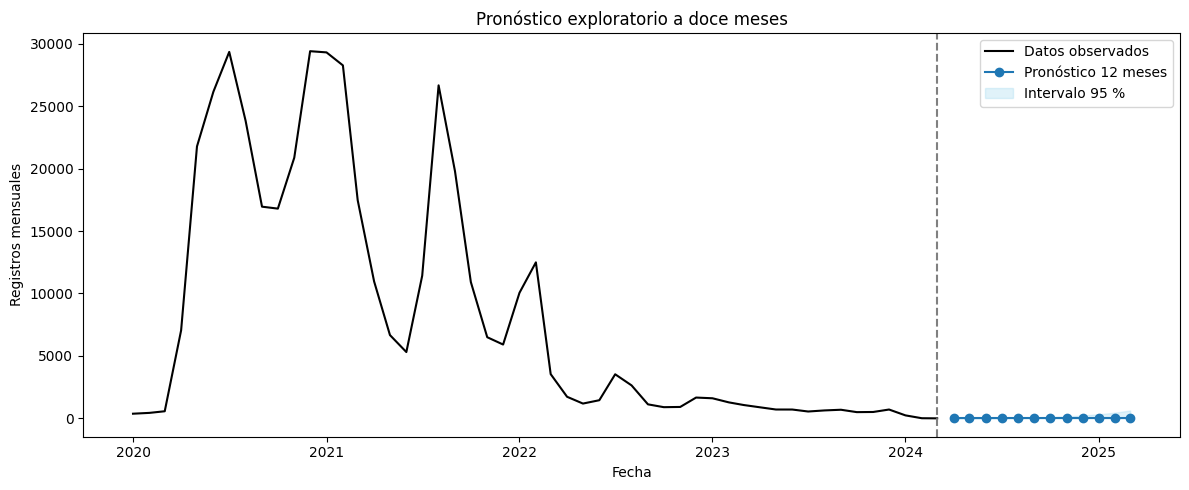

In [77]:
# Reajuste y pronóstico de abril de 2024 a marzo de 2025
ts_completa = ts_data.copy()
fit_final = ARIMA(np.log(ts_completa), order=orden_elegido, trend=tendencia_elegida).fit()
pronostico_12 = fit_final.get_forecast(steps=12)
lim80 = pronostico_12.conf_int(alpha=0.20)
lim95 = pronostico_12.conf_int(alpha=0.05)
forecast_1ano = pd.DataFrame({
    'Pronóstico': np.exp(pronostico_12.predicted_mean.to_numpy()),
    'Inferior 80%': np.exp(lim80.iloc[:, 0].to_numpy()),
    'Superior 80%': np.exp(lim80.iloc[:, 1].to_numpy()),
    'Inferior 95%': np.exp(lim95.iloc[:, 0].to_numpy()),
    'Superior 95%': np.exp(lim95.iloc[:, 1].to_numpy())
}, index=pronostico_12.predicted_mean.index)
forecast_1ano.index.name = 'Mes'
display(forecast_1ano.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ts_completa.index, ts_completa, color='black', label='Datos observados')
ax.plot(forecast_1ano.index, forecast_1ano['Pronóstico'], marker='o', color='tab:blue', label='Pronóstico 12 meses')
ax.fill_between(forecast_1ano.index, forecast_1ano['Inferior 95%'], forecast_1ano['Superior 95%'], color='skyblue', alpha=0.25, label='Intervalo 95 %')
ax.axvline(ts_completa.index[-1], color='gray', ls='--')
ax.set(title='Pronóstico exploratorio a doce meses', xlabel='Fecha', ylabel='Registros mensuales')
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación de las cifras proyectadas.** Con todos los registros, el modelo predice una **mediana aproximada de 0.55 por mes** a partir de abril de 2024. Un valor fraccionario es posible porque el ARIMA transformado genera una estimación continua; **no significa que pueda registrarse literalmente una fracción de defunción**.

Los límites superiores del 95 % crecen considerablemente con los meses (hasta aproximadamente **632.24** en marzo de 2025). Esto muestra una **incertidumbre amplia** y hace inadecuado interpretar la línea central, por sí sola, como una estimación firme. El resultado refleja especialmente el descenso hasta **11 y 1 registros** en febrero y marzo de 2024, cuya integridad no se ha confirmado.

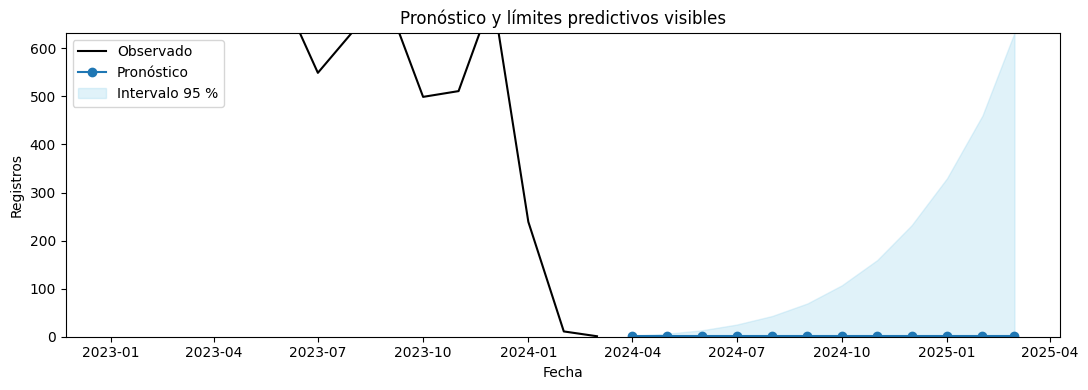

In [78]:
# Detalle de los intervalos predictivos a doce meses
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ts_completa.loc['2023':].index, ts_completa.loc['2023':], color='black', label='Observado')
ax.plot(forecast_1ano.index, forecast_1ano['Pronóstico'], color='tab:blue', marker='o', label='Pronóstico')
ax.fill_between(forecast_1ano.index, forecast_1ano['Inferior 95%'], forecast_1ano['Superior 95%'], color='skyblue', alpha=0.25, label='Intervalo 95 %')
ax.set(ylim=(0, forecast_1ano['Superior 95%'].max()), title='Pronóstico y límites predictivos visibles', xlabel='Fecha', ylabel='Registros')
ax.legend()
plt.tight_layout()
plt.show()

### Sensibilidad a la fecha de cierre

Se compara el ajuste realizado con datos hasta marzo de 2024 con otro que finaliza en enero de 2024. Así se observa cuánto cambia el pronóstico cuando se dejan fuera los dos últimos meses, cuyos conteos son **11 y 1**. Se mantiene la misma especificación del modelo y solo se modifica el periodo utilizado.

**Este recorte es una prueba de sensibilidad**, no una corrección automática ni una justificación para eliminar observaciones de la base. Las dos series de pronóstico se comparan únicamente en los meses que tienen en común.

,Corte marzo 2024,Corte enero 2024
2024-04-01,0.55,116.86
2024-05-01,0.55,116.86
2024-06-01,0.55,116.86
2024-07-01,0.55,116.86
2024-08-01,0.55,116.86
2024-09-01,0.55,116.86
2024-10-01,0.55,116.86
2024-11-01,0.55,116.86
2024-12-01,0.55,116.86
2025-01-01,0.55,116.86


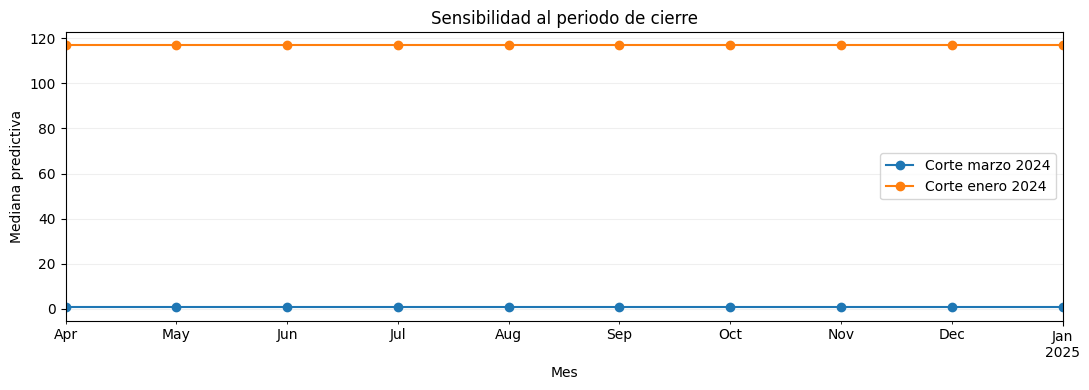

In [79]:
# Sensibilidad del pronóstico al corte de la serie
serie_hasta_enero = ts_data.loc[:'2024-01']
ajuste_hasta_enero = ARIMA(np.log(serie_hasta_enero), order=orden_elegido, trend=tendencia_elegida).fit()
pronostico_hasta_enero = ajuste_hasta_enero.get_forecast(steps=12).predicted_mean
escenarios = pd.concat([
    forecast_1ano['Pronóstico'].rename('Corte marzo 2024'),
    np.exp(pronostico_hasta_enero).rename('Corte enero 2024')
], axis=1).dropna()
display(escenarios.round(2))

fig, ax = plt.subplots(figsize=(11, 4))
escenarios.plot(ax=ax, marker='o')
ax.set(title='Sensibilidad al periodo de cierre', xlabel='Mes', ylabel='Mediana predictiva')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**¿Qué demuestra la comparación de cierres?** Para abril de 2024, el pronóstico mediano es **0.55** cuando se incluyen los registros hasta marzo y **116.86** cuando el ajuste termina en enero. Una diferencia tan grande, manteniendo el mismo tipo de ARIMA, indica **alta sensibilidad a los últimos dos meses**.

Esto **no demuestra que esos datos sean incorrectos**; señala que deben verificarse antes de usar el pronóstico para describir una trayectoria real. El análisis sirve para cuantificar incertidumbre derivada de la selección del periodo de observación.

## 8. Conclusiones y limitaciones

Los registros mensuales muestran variaciones importantes entre 2020 y 2024. Se estudiaron mediante descomposición, pruebas de estacionariedad y varios modelos ARIMA, sin pretender atribuir causalidad epidemiológica a los cambios temporales.

La división **aproximada 80/20** dejó **40 meses de entrenamiento y 11 de prueba**. Entre las especificaciones evaluadas, **ARIMA(0,1,1)** obtuvo el menor **AICc = 67.7567**. Fuera de muestra alcanzó **MAE = 369.17 y RMSE = 450.96**, ambos menores que los de la referencia ingenua. No obstante, los intervalos son amplios y el contraste Anderson–Darling señala **desviaciones respecto a la normalidad** de los residuos.

El pronóstico exploratorio para abril de 2024–marzo de 2025 es muy sensible a los últimos registros. En particular, febrero y marzo de 2024 contienen **11 y 1** observaciones, respectivamente, y su integridad aún debe verificarse. Los resultados no justifican extrapolaciones epidemiológicas definitivas.

**Alcance:** el análisis corresponde a los registros incluidos en la base, no identifica necesariamente una causa individual de defunción ni demuestra relaciones causales entre los acontecimientos y la evolución de la serie.
